# Guía 5 — Partes II y III: Potencia radiada, distribución angular y radiación dipolar

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

Problemas **4–9** de la Guía 5.

| Problema | Simulación | Idea central |
|---|---|---|
| 4 | Fotones Monte Carlo muestreados de $dP/d\Omega\propto\sin^2\theta$; integral → Larmor | $dP/d\Omega$ normalizada es una distribución de probabilidad de direcciones |
| 5 | Fracción en la banda ecuatorial: $11/16$ vs. fracción de área $1/2$ | La radiación se concentra donde $\mathbf{a}$ es transversal |
| 6 | Pulso gaussiano de aceleración: campo, potencia, energía y **espectro** | Pulsos cortos ⇒ espectro ancho (bremsstrahlung) |
| 7 | Dipolo armónico (ver también la Guía 6) | $\langle P\rangle\propto\omega^4$ |
| 8 | Dipolo que **gira**: patrón instantáneo rotando (animación) y patrón promedio $(1+\cos^2\theta)/2$ | Dos dipolos en cuadratura: potencia constante y el doble |
| 9 | Oscilador con amortiguamiento radiativo; tiempos de vida y anchos de línea reales | El tiempo de vida atómico clásico $\sim10\,$ns |

**Unidades:** $c=1$ y $q/4\pi\varepsilon_0=1$ (o $1/4\pi\varepsilon_0=1$ para dipolos). Así, $dP/d\Omega=\frac{1}{4\pi}|\hat{n}\times(\hat{n}\times\mathbf{a})|^2$ y Larmor queda $P=\frac23a^2$ (o $\frac23|\ddot{\mathbf{p}}|^2$). Donde hay números reales, se dan en SI.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.integrate import solve_ivp

import em_utils as u
u.estilo()
C = u.COLORES
rng = np.random.default_rng(2026)

---
## Problema 4 — Distribución angular y fórmula de Larmor

$|\hat{n}\times(\hat{n}\times\mathbf{a})|=a\sin\theta$ ⇒ $\dfrac{dP}{d\Omega}=\dfrac{q^2a^2}{16\pi^2\varepsilon_0c^3}\sin^2\theta$, máxima en $\theta=\pi/2$ y nula en $\theta=0,\pi$. Integrando con $\int_0^\pi\sin^3\theta\,d\theta=4/3$:

$$P=\frac{q^2a^2}{16\pi^2\varepsilon_0c^3}\cdot2\pi\cdot\frac43=\frac{q^2a^2}{6\pi\varepsilon_0c^3}\qquad\text{(Larmor)}.$$

**Una mirada probabilística.** $f(\hat{n})=\frac{1}{P}\frac{dP}{d\Omega}=\frac{3}{8\pi}\sin^2\theta$ es una densidad de probabilidad sobre la esfera: la distribución de direcciones de los "fotones" emitidos. Muestreamos $2\times10^5$ direcciones por **rechazo** y comprobamos que reproducen la distribución, sin usar la fórmula analítica en el muestreo más allá de la forma $\sin^2\theta$.

∮ dP/dΩ dΩ = 0.66666667 a²   (Larmor en estas unidades: 2/3 = 0.66666667)


[guardado] figuras/P4_fotones_monte_carlo_larmor.png


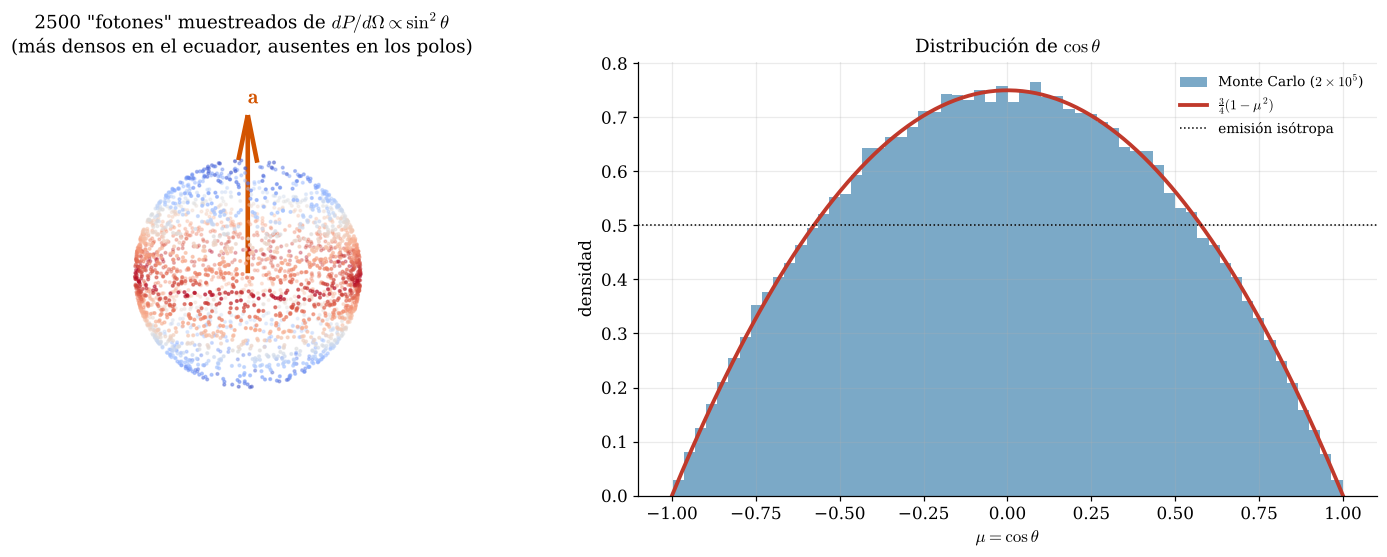

In [2]:
I = u.integrar_esfera(lambda n: (1 - n[..., 2]**2)/(4*np.pi))
print(f"∮ dP/dΩ dΩ = {I:.8f} a²   (Larmor en estas unidades: 2/3 = {2/3:.8f})")

def muestrear_fotones(N):
    # rechazo: μ uniforme en [-1,1], se acepta con prob. (1-μ²)
    out = []
    while sum(len(o) for o in out) < N:
        mu = rng.uniform(-1, 1, 2*N); acept = rng.uniform(0, 1, 2*N) < 1 - mu**2
        out.append(mu[acept])
    mu = np.concatenate(out)[:N]
    ph = rng.uniform(0, 2*np.pi, N)
    s = np.sqrt(1 - mu**2)
    return np.stack([s*np.cos(ph), s*np.sin(ph), mu], -1)

fot = muestrear_fotones(200_000)
fig = plt.figure(figsize=(14, 5.2))
A = fig.add_subplot(1, 2, 1, projection='3d')
m = fot[:2500]
A.scatter(*m.T, s=3, c=np.abs(m[:, 2]), cmap='coolwarm_r', alpha=0.8)
A.quiver(0, 0, 0, 0, 0, 1.4, color=C['a'], lw=3); A.text(0, 0, 1.5, r'$\mathbf{a}$', color=C['a'], fontsize=14)
A.set_box_aspect((1, 1, 1)); A.set_axis_off(); A.view_init(elev=12, azim=-50)
A.set_title('2500 "fotones" muestreados de $dP/d\\Omega\\propto\\sin^2\\theta$\n(más densos en el ecuador, ausentes en los polos)')
A = fig.add_subplot(1, 2, 2)
A.hist(fot[:, 2], bins=60, density=True, color=C['B'], alpha=0.6, label='Monte Carlo ($2\\times10^5$)')
mu = np.linspace(-1, 1, 200)
A.plot(mu, 0.75*(1 - mu**2), color=C['E'], lw=2.5, label=r'$\frac{3}{4}(1-\mu^2)$')
A.axhline(0.5, color='k', ls=':', lw=1, label='emisión isótropa')
A.set_xlabel(r'$\mu=\cos\theta$'); A.set_ylabel('densidad'); A.legend(fontsize=9)
A.set_title(r'Distribución de $\cos\theta$')
fig.tight_layout(); u.guardar(fig, 'P4_fotones_monte_carlo_larmor'); plt.show()

---
## Problema 5 — ¿Qué fracción llega al ecuador?

Para la banda $\pi/3\le\theta\le2\pi/3$, es decir $|\mu|\le\frac12$:

$$f=\frac{\int_{-1/2}^{1/2}(1-\mu^2)\,d\mu}{\int_{-1}^{1}(1-\mu^2)\,d\mu}=\frac{1-\frac1{12}}{\frac43}=\frac{11/12}{4/3}=\boxed{\frac{11}{16}}=0.6875 .$$

La banda ocupa solo **la mitad del área** de la esfera ($\Delta\mu/2=1/2$), pero recibe casi el 70 % de la potencia, porque el patrón pesa más las direcciones transversales a $\mathbf{a}$. En general, para la banda $|\mu|\le s$, $f(s)=\frac{3s-s^3}{2}$ frente a la fracción de área $s$.

fracción Monte Carlo = 0.6877 ± 0.0010    exacta 11/16 = 0.6875    área = 0.5


[guardado] figuras/P5_fraccion_banda_ecuatorial.png


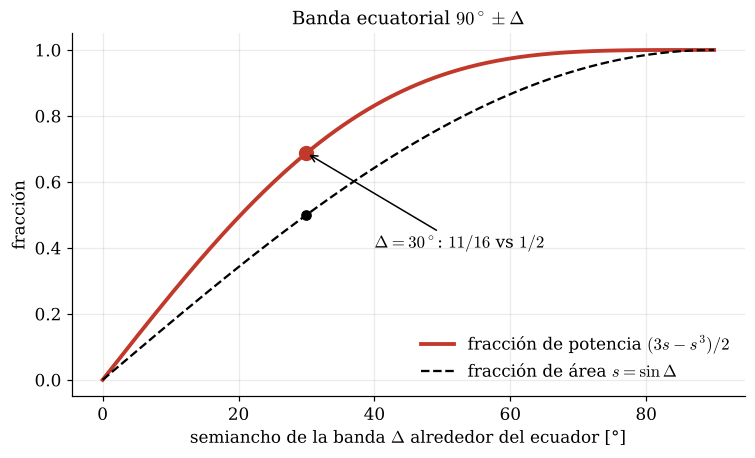

In [3]:
f_mc = np.mean(np.abs(fot[:, 2]) <= 0.5)
print(f"fracción Monte Carlo = {f_mc:.4f} ± {np.sqrt(f_mc*(1-f_mc)/len(fot)):.4f}    exacta 11/16 = {11/16:.4f}    área = 0.5")

D = np.linspace(0, 90, 300); s = np.sin(np.radians(D))
fig, A = plt.subplots(figsize=(7, 4.3))
A.plot(D, (3*s - s**3)/2, color=C['E'], lw=2.5, label=r'fracción de potencia $(3s-s^3)/2$')
A.plot(D, s, color='k', lw=1.5, ls='--', label=r'fracción de área $s=\sin\Delta$')
A.plot(30, 11/16, 'o', color=C['E'], ms=9); A.annotate(r'$\Delta=30^\circ$: $11/16$ vs $1/2$', (30, 11/16), (40, 0.4), arrowprops=dict(arrowstyle='->'))
A.plot(30, 0.5, 'o', color='k', ms=6)
A.set_xlabel(r'semiancho de la banda $\Delta$ alrededor del ecuador [°]'); A.set_ylabel('fracción')
A.set_title('Banda ecuatorial $90^\\circ\\pm\\Delta$'); A.legend()
fig.tight_layout(); u.guardar(fig, 'P5_fraccion_banda_ecuatorial'); plt.show()

---
## Problema 6 — Un pulso de aceleración ⋆

$\mathbf{a}(t_r)=a_0e^{-t_r^2/\tau^2}\hat{z}$. Con la ec. (3):

$$\mathbf{E}_{\rm rad}(R,\theta,t)=\frac{q\,a_0\sin\theta}{4\pi\varepsilon_0c^2R}\,e^{-(t-R/c)^2/\tau^2}\,\hat\theta,\qquad
P(t_r)=\frac{q^2a_0^2}{6\pi\varepsilon_0c^3}e^{-2t_r^2/\tau^2},\qquad
W=\frac{q^2a_0^2}{6\pi\varepsilon_0c^3}\,\tau\sqrt{\frac\pi2}.$$

Duplicar $a_0$ cuadruplica $W$; duplicar $\tau$ lo duplica: $W\propto a_0^2\tau$.

**Más allá de la guía: el espectro.** Por Parseval, la energía se reparte en frecuencias según $|\tilde a(\omega)|^2$:

$$\frac{dW}{d\omega}=\frac{q^2}{6\pi^2\varepsilon_0c^3}|\tilde a(\omega)|^2,\qquad|\tilde a(\omega)|^2=\pi a_0^2\tau^2e^{-\omega^2\tau^2/2}.$$

Un pulso de duración $\tau$ emite en un ancho $\Delta\omega\sim1/\tau$. Es el principio del *bremsstrahlung*: un frenado brusco produce un espectro ancho, hasta rayos X.

[guardado] figuras/P6_pulso_aceleracion_energia.png


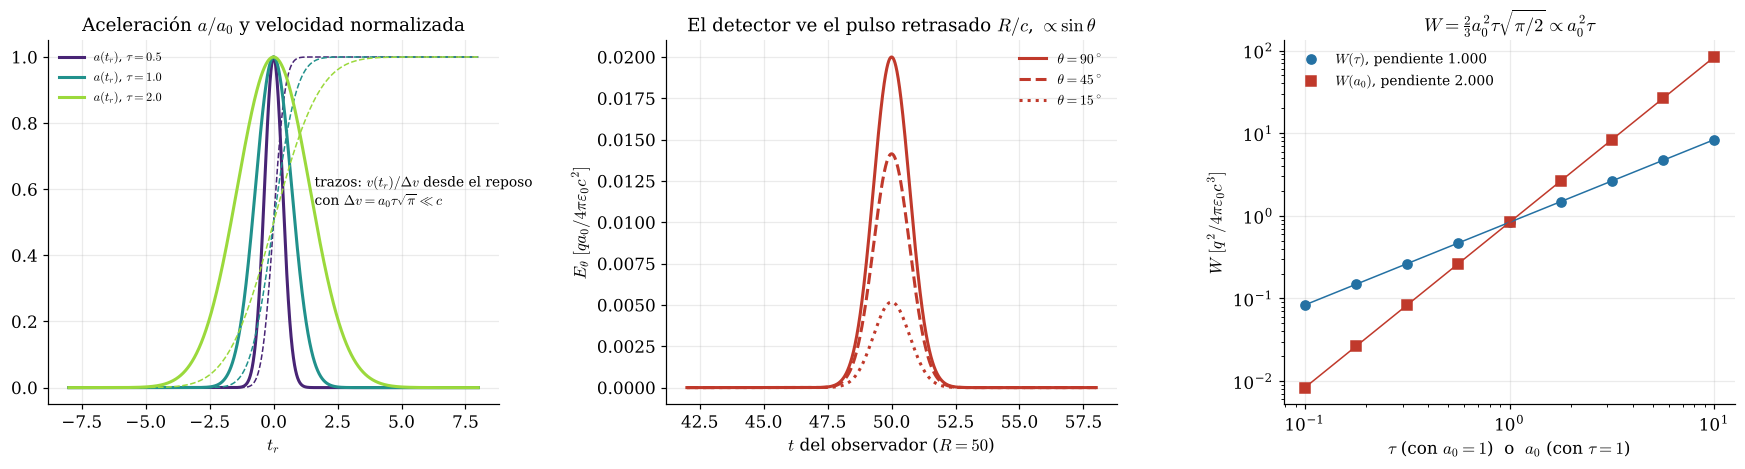

W numérico (a0=τ=1) = 0.83554276   analítico (2/3)√(π/2) = 0.83554276


In [4]:
from scipy.special import erf
def pulso(t, a0, tau):
    return a0*np.exp(-t**2/tau**2)

t = np.linspace(-8, 8, 4001)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
A = ax[0]
for tau, col in zip([0.5, 1.0, 2.0], plt.cm.viridis([0.1, 0.5, 0.85])):
    A.plot(t, pulso(t, 1, tau), color=col, lw=2, label=fr'$a(t_r)$, $\tau={tau}$')
    A.plot(t, 0.5*(1 + erf(t/tau)), color=col, lw=1, ls='--')
A.text(1.6, 0.55, r'trazos: $v(t_r)/\Delta v$ desde el reposo' + '\n' + r'con $\Delta v=a_0\tau\sqrt{\pi}\ll c$', fontsize=9)
A.set_xlabel(r'$t_r$'); A.set_title(r'Aceleración $a/a_0$ y velocidad normalizada'); A.legend(fontsize=8, loc='upper left')

A = ax[1]
R = 50.0
for th, ls in [(90, '-'), (45, '--'), (15, ':')]:
    A.plot(t + R, np.sin(np.radians(th))*pulso(t, 1, 1.0)/R, color=C['E'], ls=ls, lw=2, label=fr'$\theta={th}^\circ$')
A.set_xlabel(r'$t$ del observador ($R=50$)'); A.set_ylabel(r'$E_\theta\;[q a_0/4\pi\varepsilon_0c^2]$')
A.set_title(r'El detector ve el pulso retrasado $R/c$, $\propto\sin\theta$'); A.legend(fontsize=9)

A = ax[2]
taus = np.logspace(-1, 1, 9); a0s = np.logspace(-1, 1, 9)
W_tau = [np.trapezoid((2/3)*pulso(t*max(1, tt), 1, tt)**2, t*max(1, tt)) for tt in taus]
W_a0 = [np.trapezoid((2/3)*pulso(t, aa, 1.0)**2, t) for aa in a0s]
A.loglog(taus, W_tau, 'o', color=C['B'], label=fr'$W(\tau)$, pendiente {np.polyfit(np.log(taus), np.log(W_tau), 1)[0]:.3f}')
A.loglog(a0s, W_a0, 's', color=C['E'], label=fr'$W(a_0)$, pendiente {np.polyfit(np.log(a0s), np.log(W_a0), 1)[0]:.3f}')
A.loglog(taus, (2/3)*taus*np.sqrt(np.pi/2), color=C['B'], lw=1)
A.loglog(a0s, (2/3)*a0s**2*np.sqrt(np.pi/2), color=C['E'], lw=1)
A.set_xlabel(r'$\tau$ (con $a_0=1$)  o  $a_0$ (con $\tau=1$)'); A.set_ylabel(r'$W\;[q^2/4\pi\varepsilon_0 c^3]$')
A.set_title(r'$W=\frac{2}{3}a_0^2\tau\sqrt{\pi/2}\propto a_0^2\tau$'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P6_pulso_aceleracion_energia'); plt.show()
print(f"W numérico (a0=τ=1) = {np.trapezoid((2/3)*pulso(t,1,1)**2, t):.8f}   analítico (2/3)√(π/2) = {(2/3)*np.sqrt(np.pi/2):.8f}")

[guardado] figuras/P6_espectro_pulso.png


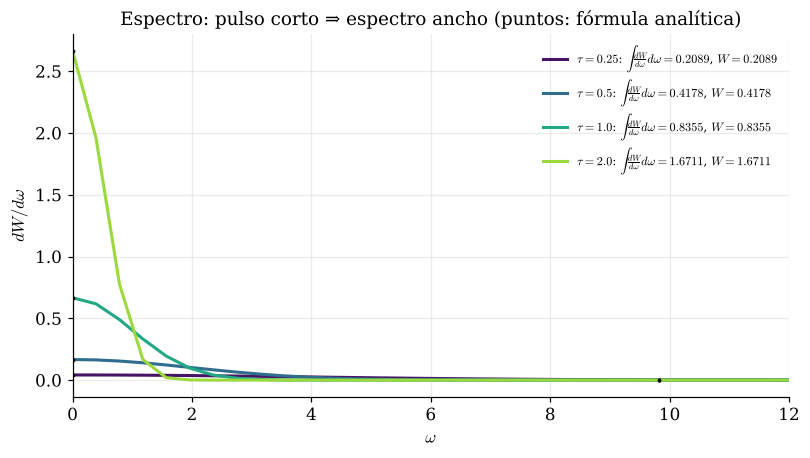

In [5]:
# espectro por FFT y verificación de Parseval
dt = t[1] - t[0]
fig, A = plt.subplots(figsize=(7.5, 4.3))
for tau, col in zip([0.25, 0.5, 1.0, 2.0], plt.cm.viridis([0.05, 0.35, 0.6, 0.85])):
    a_t = pulso(t, 1, tau)
    at = np.fft.rfft(a_t)*dt                       # ã(ω) = ∫ a(t) e^{-iωt} dt
    om = 2*np.pi*np.fft.rfftfreq(len(t), dt)
    dWdw = (2/3)/np.pi*np.abs(at)**2               # unidades: q²/(4π ε0 c³) = 1
    W_spec = np.trapezoid(dWdw, om); W_t = np.trapezoid((2/3)*a_t**2, t)
    A.plot(om, dWdw, color=col, lw=2, label=fr'$\tau={tau}$: $\int\frac{{dW}}{{d\omega}}d\omega={W_spec:.4f}$, $W={W_t:.4f}$')
    A.plot(om[::25], (2/3)*tau**2*np.exp(-om[::25]**2*tau**2/2), 'k.', ms=3)
A.set_xlim(0, 12); A.set_xlabel(r'$\omega$'); A.set_ylabel(r'$dW/d\omega$')
A.set_title('Espectro: pulso corto ⇒ espectro ancho (puntos: fórmula analítica)'); A.legend(fontsize=8)
fig.tight_layout(); u.guardar(fig, 'P6_espectro_pulso'); plt.show()

---
## Problema 7 — Dipolo eléctrico armónico

Es el mismo sistema del Problema 3 de la Guía 6. En `../Guia_06_Radiacion_Covarianza/01_radiacion.ipynb` está la versión completa: campos cercano y lejano, líneas de campo que se desprenden (animación) y la ley $\omega^4$ aplicada al cielo azul. Aquí solo verificamos los números que pide la guía:

$$\mathbf{E}_{\rm rad}=-\frac{\mu_0p_0\omega^2}{4\pi}\frac{\sin\theta}{r}\cos[\omega(t-r/c)]\hat\theta,\qquad\Big\langle\frac{dP}{d\Omega}\Big\rangle=\frac{\mu_0p_0^2\omega^4}{32\pi^2c}\sin^2\theta,\qquad\langle P\rangle=\frac{\mu_0p_0^2\omega^4}{12\pi c}.$$

In [6]:
def P_media_dipolo(p_fun, w, n_t=400):
    ts = np.linspace(0, 2*np.pi/w, n_t, endpoint=False)
    pdd = np.array([p_fun(tt, w) for tt in ts])        # p̈(t)
    return np.mean((2/3)*np.sum(pdd**2, -1))           # Larmor con q a -> p̈  (1/4πε0 = 1, c = 1)
lineal = lambda tt, w: -w**2*np.array([0, 0, np.cos(w*tt)])
for w in [1.0, 2.0]:
    print(f"ω = {w}:  <P> numérico = {P_media_dipolo(lineal, w):.6f}   fórmula p0²ω⁴/3 = {w**4/3:.6f}")
print("cociente <P>(2ω)/<P>(ω) =", P_media_dipolo(lineal, 2.0)/P_media_dipolo(lineal, 1.0))

ω = 1.0:  <P> numérico = 0.333333   fórmula p0²ω⁴/3 = 0.333333
ω = 2.0:  <P> numérico = 5.333333   fórmula p0²ω⁴/3 = 5.333333
cociente <P>(2ω)/<P>(ω) = 16.0


---
## Problema 8 — Dipolo cuyo momento gira en un plano ⋆

$\mathbf{p}=p_0(\cos\omega t\,\hat{x}+\sin\omega t\,\hat{y})$ ⇒ $\ddot{\mathbf{p}}=-\omega^2\mathbf{p}$ y $|\ddot{\mathbf{p}}|^2=\omega^4p_0^2$ **constante**:

$$P=\frac{p_0^2\omega^4}{6\pi\varepsilon_0c^3}\quad\text{(constante en el tiempo)} .$$

El patrón instantáneo es la dona $\sin^2\alpha$ alrededor de $\ddot{\mathbf{p}}$, que **gira** con el dipolo como un faro. Promediando, con $\hat{n}\cdot\hat{p}=\sin\theta\cos(\phi-\omega t)$ y $\langle\cos^2\rangle=\frac12$:

$$\Big\langle\frac{dP}{d\Omega}\Big\rangle=\frac{p_0^2\omega^4}{16\pi^2\varepsilon_0c^3}\Big(1-\tfrac12\sin^2\theta\Big)=\frac{p_0^2\omega^4}{16\pi^2\varepsilon_0c^3}\,\frac{1+\cos^2\theta}{2},$$

que **no** se anula en ningún lado. Integrando, $\int\frac{1+\cos^2\theta}{2}d\Omega=\frac{8\pi}{3}$, y se recupera la $P$ de arriba.

**Comparación con el dipolo lineal.** El dipolo lineal tiene $\langle P\rangle=\frac{p_0^2\omega^4}{12\pi\varepsilon_0c^3}$: el rotante radia **el doble**. Son dos dipolos lineales perpendiculares de amplitud $p_0$, en cuadratura. Sus potencias se suman (el término cruzado promedia cero) y $|\ddot{\mathbf{p}}|^2$ nunca pasa por cero.

*Conexión:* un pulsar es, en primera aproximación, un **dipolo magnético rotante** inclinado respecto del eje de giro. Su potencia $\propto\mu^2\omega^4$ frena la estrella (*spin-down*), y la emisión en haz barre el cielo como este patrón.

<P> rotante = 0.666667  (2/3 = 0.666667),  <P> lineal = 0.333333,  cociente = 2.0000
máx |patrón promedio numérico - (1+cos²θ)/(8π)| = 4.163336342344337e-17
∮ <dP/dΩ> dΩ = 0.6666666666666655   (2/3)


[guardado] figuras/P8_dipolo_rotante_vs_lineal.png


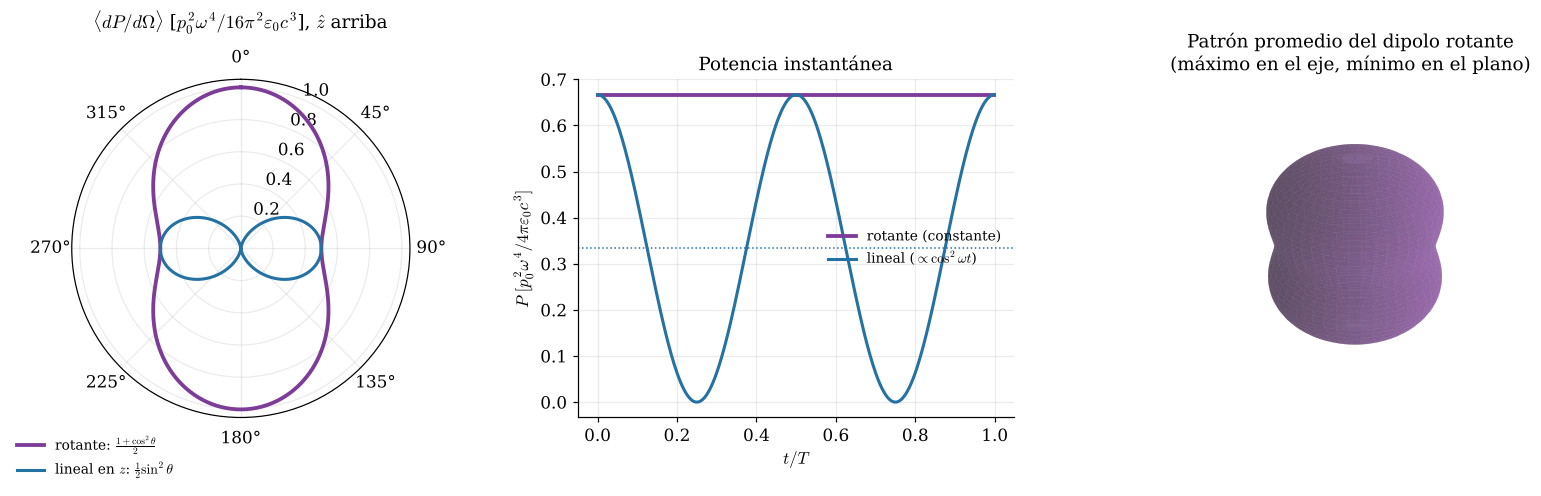

In [7]:
w = 1.0
ts = np.linspace(0, 2*np.pi, 400, endpoint=False)
rot = lambda tt, w: -w**2*np.array([np.cos(w*tt), np.sin(w*tt), 0])
P_rot_t = [(2/3)*np.sum(rot(tt, w)**2) for tt in ts]
P_lin_t = [(2/3)*np.sum(lineal(tt, w)**2) for tt in ts]
print(f"<P> rotante = {np.mean(P_rot_t):.6f}  (2/3 = {2/3:.6f}),  <P> lineal = {np.mean(P_lin_t):.6f},  cociente = {np.mean(P_rot_t)/np.mean(P_lin_t):.4f}")

# patrón promedio numérico (promediando el patrón instantáneo) vs (1+cos²θ)/2
TH, PH, N = u.esfera(91, 181)
prom = np.zeros(TH.shape)
for tt in ts[::8]:
    pdd = rot(tt, w); prom += (np.sum(pdd**2) - (N @ pdd)**2)/(4*np.pi)
prom /= len(ts[::8])
print("máx |patrón promedio numérico - (1+cos²θ)/(8π)| =", np.abs(prom - (1 + np.cos(TH)**2)/(8*np.pi)).max())
print("∮ <dP/dΩ> dΩ =", u.integrar_esfera(lambda n: (1 + n[..., 2]**2)/(8*np.pi)), "  (2/3)")

fig = plt.figure(figsize=(15, 4.6))
A = fig.add_subplot(1, 3, 1, projection='polar')
thp = np.linspace(0, 2*np.pi, 400)
A.plot(thp, (1 + np.cos(thp)**2)/2, color=C['S'], lw=2.5, label=r'rotante: $\frac{1+\cos^2\theta}{2}$')
A.plot(thp, np.sin(thp)**2/2, color=C['B'], lw=2, label=r'lineal en $z$: $\frac{1}{2}\sin^2\theta$')
A.set_theta_zero_location('N'); A.set_theta_direction(-1)
A.set_title(r'$\langle dP/d\Omega\rangle$ [$p_0^2\omega^4/16\pi^2\varepsilon_0c^3$], $\hat{z}$ arriba', pad=14)
A.legend(loc='lower left', bbox_to_anchor=(-0.2, -0.22), fontsize=9)
A = fig.add_subplot(1, 3, 2)
A.plot(ts/(2*np.pi), P_rot_t, color=C['S'], lw=2.5, label='rotante (constante)')
A.plot(ts/(2*np.pi), P_lin_t, color=C['B'], lw=2, label=r'lineal ($\propto\cos^2\omega t$)')
A.axhline(np.mean(P_lin_t), color=C['B'], ls=':', lw=1)
A.set_xlabel(r'$t/T$'); A.set_ylabel(r'$P\;[p_0^2\omega^4/4\pi\varepsilon_0c^3]$'); A.legend(fontsize=9)
A.set_title('Potencia instantánea')
A = fig.add_subplot(1, 3, 3, projection='3d')
Rr = (1 + np.cos(TH)**2)/2
X, Y, Z = (Rr[..., None]*N).transpose(2, 0, 1)
A.plot_surface(X, Y, Z, color=C['S'], alpha=0.5, linewidth=0)
A.set_box_aspect((1, 1, 1)); A.set_axis_off(); A.set_title('Patrón promedio del dipolo rotante\n(máximo en el eje, mínimo en el plano)')
fig.tight_layout(); u.guardar(fig, 'P8_dipolo_rotante_vs_lineal'); plt.show()

In [8]:
TH2, PH2, N2 = u.esfera(61, 121)
fig = plt.figure(figsize=(10, 5))
A1 = fig.add_subplot(1, 2, 1, projection='3d'); A2 = fig.add_subplot(1, 2, 2, projection='3d')
Rm = (1 + np.cos(TH2)**2)/2
Xm, Ym, Zm = (Rm[..., None]*N2).transpose(2, 0, 1)
def cuadro(i):
    tt = 2*np.pi*i/36
    pdd = rot(tt, w); ph = pdd/np.linalg.norm(pdd)
    Rr = 1 - (N2 @ ph)**2
    X, Y, Z = (Rr[..., None]*N2).transpose(2, 0, 1)
    for A in (A1, A2):
        A.cla(); A.set_box_aspect((1, 1, 1)); A.set_axis_off(); A.view_init(elev=25, azim=-60)
        A.set_xlim(-1, 1); A.set_ylim(-1, 1); A.set_zlim(-1, 1)
    A1.plot_surface(X, Y, Z, facecolors=plt.cm.plasma(Rr), linewidth=0, alpha=0.9)
    A1.quiver(0, 0, 0, *(1.3*np.array([np.cos(tt), np.sin(tt), 0])), color='k', lw=2.5)
    A1.set_title(f'Instantáneo, $\\omega t={np.degrees(tt):.0f}^\\circ$\n(dona alrededor de $\\mathbf{{p}}$)')
    A2.plot_surface(Xm, Ym, Zm, color=C['S'], alpha=0.45, linewidth=0)
    A2.plot_surface(X, Y, Z, facecolors=plt.cm.plasma(Rr), linewidth=0, alpha=0.25)
    A2.set_title('Promedio en un período\n$(1+\\cos^2\\theta)/2$')
anim = animation.FuncAnimation(fig, cuadro, frames=36)
u.guardar_gif(anim, 'P8_animacion_dipolo_rotante', fps=12, dpi=70)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P8_animacion_dipolo_rotante.gif)

[guardado] figuras/P8_animacion_dipolo_rotante.gif  (0.77 MB)


![animación](figuras/P8_animacion_dipolo_rotante.gif)

---
## Problema 9 — Tiempo característico de pérdida de energía ⋆

Para $x=A\cos\omega t$: $\langle a^2\rangle=\frac12\omega^4A^2$, de modo que

$$\langle P\rangle=\frac{q^2\omega^4A^2}{12\pi\varepsilon_0c^3},\qquad E_{\rm mec}=\tfrac12m\omega^2A^2,\qquad
\boxed{\tau_E=\frac{E_{\rm mec}}{\langle P\rangle}=\frac{6\pi\varepsilon_0mc^3}{q^2\omega^2}=\frac{1}{\omega^2\tau_q}},\qquad\tau_q\equiv\frac{q^2}{6\pi\varepsilon_0mc^3}.$$

Para el electrón, $\tau_e=6.26\times10^{-24}\,$s: el tiempo que tarda la luz en cruzar su radio clásico. La aproximación ("$A$ y $\omega$ constantes durante un período") exige $\tau_E\gg2\pi/\omega$, es decir $\omega\tau_q\ll1/2\pi$.

**Simulación.** La fuerza de Abraham–Lorentz $m\tau_q\dddot x$ tiene soluciones desbocadas. La forma reducida de Landau–Lifshitz evalúa $\dddot x$ sobre la solución sin radiación, $\dddot x\simeq-\omega^2\dot x$:

$$\ddot x=-\omega^2x-\omega^2\tau_q\,\dot x ,$$

un oscilador amortiguado con tasa de pérdida de energía $\Gamma=\omega^2\tau_q=1/\tau_E$. Exageramos $\epsilon\equiv\omega\tau_q$ para hacer visible el efecto y comparamos la energía con $e^{-t/\tau_E}$.

ε = 0.02:  τ_E = 1/ε =   50.00 (en 1/ω),  τ_E/T =   7.96,  pérdida en 1 período = 11.8 %


ε = 0.1:  τ_E = 1/ε =   10.00 (en 1/ω),  τ_E/T =   1.59,  pérdida en 1 período = 46.7 %


ε = 0.5:  τ_E = 1/ε =    2.00 (en 1/ω),  τ_E/T =   0.32,  pérdida en 1 período = 95.7 %


[guardado] figuras/P9_amortiguamiento_radiativo.png


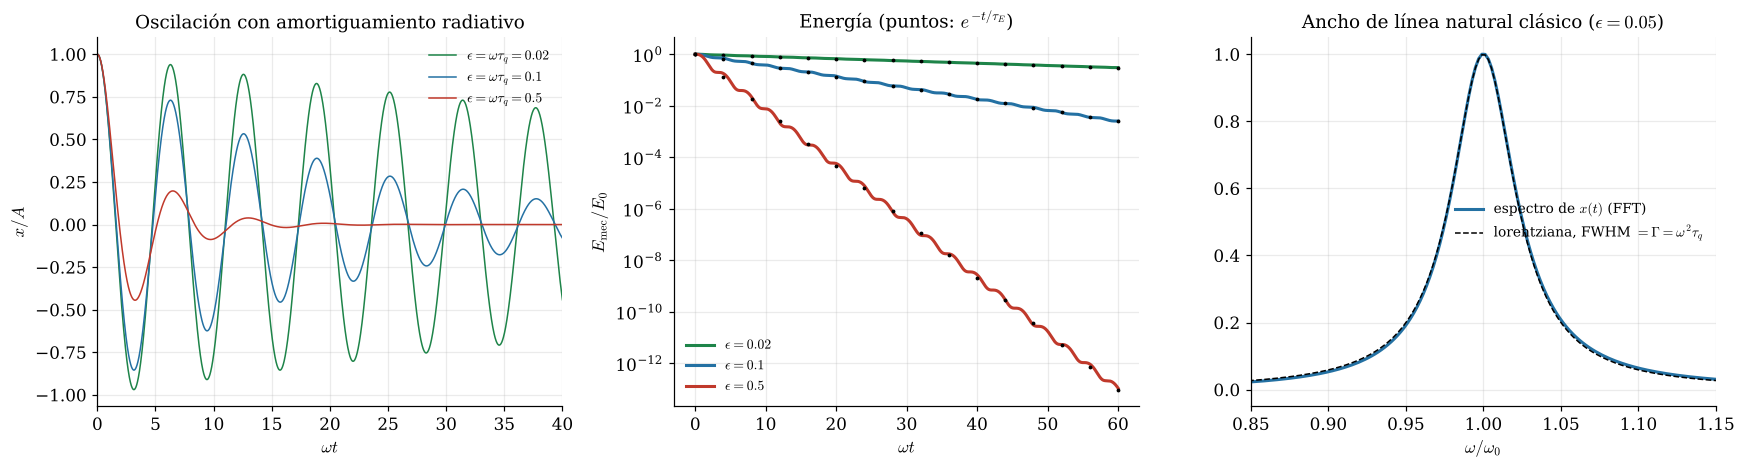

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for eps, col in zip([0.02, 0.1, 0.5], [C['v'], C['B'], C['E']]):
    sol = solve_ivp(lambda t, y: [y[1], -y[0] - eps*y[1]], (0, 60), [1, 0], max_step=0.01, rtol=1e-10, atol=1e-12)
    tt, x, v = sol.t, sol.y[0], sol.y[1]
    E = 0.5*(v**2 + x**2)
    ax[0].plot(tt, x, color=col, lw=1, label=fr'$\epsilon=\omega\tau_q={eps}$')
    ax[1].semilogy(tt, E/E[0], color=col, lw=2, label=fr'$\epsilon={eps}$')
    ax[1].semilogy(tt[::400], np.exp(-eps*tt[::400]), 'k.', ms=3)
    T_per = 2*np.pi
    print(f"ε = {eps}:  τ_E = 1/ε = {1/eps:7.2f} (en 1/ω),  τ_E/T = {1/eps/T_per:6.2f},  "
          f"pérdida en 1 período = {100*(1 - np.exp(-eps*T_per)):.1f} %")
ax[0].set_xlim(0, 40); ax[0].set_xlabel(r'$\omega t$'); ax[0].set_ylabel(r'$x/A$'); ax[0].legend(fontsize=9)
ax[0].set_title('Oscilación con amortiguamiento radiativo')
ax[1].set_xlabel(r'$\omega t$'); ax[1].set_ylabel(r'$E_{\rm mec}/E_0$'); ax[1].legend(fontsize=9)
ax[1].set_title(r'Energía (puntos: $e^{-t/\tau_E}$)')

# espectro: lorentziana de ancho Γ = 1/τ_E
eps = 0.05
sol = solve_ivp(lambda t, y: [y[1], -y[0] - eps*y[1]], (0, 3000), [1, 0], t_eval=np.linspace(0, 3000, 2**18), rtol=1e-10, atol=1e-12)
X = np.fft.rfft(sol.y[0]); om = 2*np.pi*np.fft.rfftfreq(len(sol.t), sol.t[1] - sol.t[0])
Sp = np.abs(X)**2; Sp /= Sp.max()
lor = (eps/2)**2/((om - 1)**2 + (eps/2)**2)
A = ax[2]
A.plot(om, Sp, color=C['B'], lw=2, label='espectro de $x(t)$ (FFT)')
A.plot(om, lor, 'k--', lw=1, label=r'lorentziana, FWHM $=\Gamma=\omega^2\tau_q$')
A.set_xlim(0.85, 1.15); A.set_xlabel(r'$\omega/\omega_0$'); A.set_title(f'Ancho de línea natural clásico ($\\epsilon={eps}$)'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P9_amortiguamiento_radiativo'); plt.show()

In [10]:
# números reales para un electrón
e, me, c, eps0 = 1.602176634e-19, 9.1093837e-31, 2.99792458e8, 8.8541878128e-12
tau_e = e**2/(6*np.pi*eps0*me*c**3)
print(f"τ_e = {tau_e:.3e} s     (radio clásico / c = {2.8179403e-15/c:.3e} s; τ_e = (2/3) r_e/c)")
print(f"ancho de línea clásico Δλ = 2π c τ_e = {2*np.pi*c*tau_e*1e15:.2f} fm = {2*np.pi*c*tau_e*1e9:.2e} nm  (¡independiente de λ!)\n")
print("   región           λ          ω [rad/s]     τ_E = 1/(ω²τ_e)      τ_E / período")
for nombre, lam in [('radio FM', 3.0), ('microondas', 1e-2), ('visible', 500e-9), ('rayos X', 1e-10)]:
    om = 2*np.pi*c/lam
    tE = 1/(om**2*tau_e)
    print(f"  {nombre:12s} {lam:10.2e} m   {om:10.3e}     {tE:12.3e} s       {tE/(2*np.pi/om):10.3e}")
print("\nVisible: τ_E ~ 10 ns, del orden de las vidas medias atómicas reales (p. ej. 2p→1s del H: 1.6 ns).")

τ_e = 6.266e-24 s     (radio clásico / c = 9.400e-24 s; τ_e = (2/3) r_e/c)
ancho de línea clásico Δλ = 2π c τ_e = 11.80 fm = 1.18e-05 nm  (¡independiente de λ!)

   región           λ          ω [rad/s]     τ_E = 1/(ω²τ_e)      τ_E / período
  radio FM       3.00e+00 m    6.279e+08        4.048e+05 s        4.045e+13
  microondas     1.00e-02 m    1.884e+11        4.498e+00 s        1.348e+11
  visible        5.00e-07 m    3.767e+15        1.124e-08 s        6.742e+06
  rayos X        1.00e-10 m    1.884e+19        4.498e-16 s        1.348e+03

Visible: τ_E ~ 10 ns, del orden de las vidas medias atómicas reales (p. ej. 2p→1s del H: 1.6 ns).
